In [1]:
# Cell 1: setup
import sys
from pathlib import Path

ROOT_DIR = Path(r"D:\shrey\Documents\ML- PROJECT")
sys.path.insert(0, str(ROOT_DIR))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import config as cfg
from src.features import ACAD, OA, INTERVIEW, EXCLUDED
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer

df = pd.read_csv(cfg.PROCESSED_DIR / "placement_clean.csv")
d = df[df["oa_cleared"].astype(str) == "True"].copy()
d["selected"] = (d["selected"].astype(str) == "True").astype(int)
candidates = ACAD + OA + INTERVIEW
print(d.shape, d["selected"].sum())

(960, 21) 96


In [2]:
# Cell 2: excluded columns and why (leakage table)
pd.Series(EXCLUDED, name="reason")

final_score         outcome used to pick the selected candidates (...
oa_total             weighted sum of the five OA sections (redundant)
oa_cleared                                    outcome of the OA stage
eligible                                outcome of rule-based stage 1
selected                                                   the target
application_id                                             identifier
student_id                  identifier (used only for grouped splits)
company_id              label of the company, not a student attribute
company_category        label of the company, not a student attribute
Name: reason, dtype: str

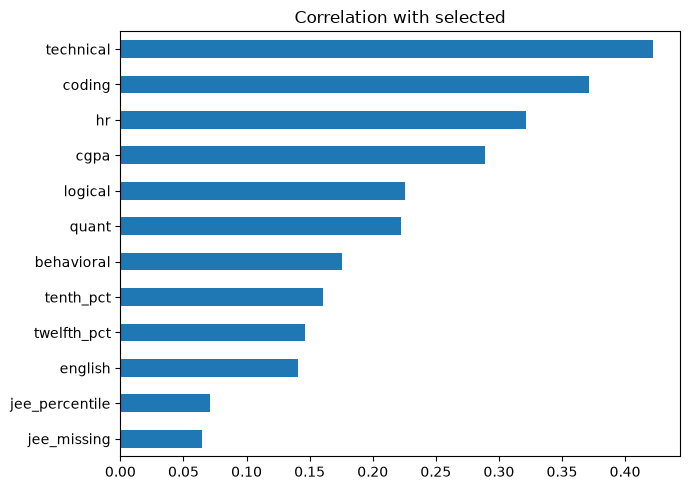

In [3]:
# Cell 3: correlation of each candidate with selected
corr = d[candidates + ["selected"]].corr()["selected"].drop("selected").sort_values()
corr.plot(kind="barh", figsize=(7, 5), title="Correlation with selected")
plt.tight_layout()
plt.savefig(cfg.VISUALS_DIR / "08_feature_corr_selected.png", dpi=150)
plt.show()

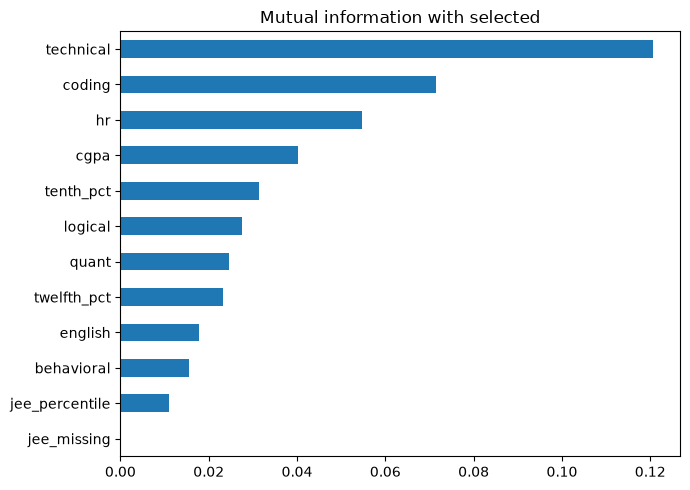

In [4]:
# Cell 4: mutual information (catches non-linear signal too)
X = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(d[candidates]), columns=candidates)
mi = pd.Series(mutual_info_classif(X, d["selected"], random_state=cfg.SEED), index=candidates).sort_values()
mi.plot(kind="barh", figsize=(7, 5), title="Mutual information with selected")
plt.tight_layout()
plt.savefig(cfg.VISUALS_DIR / "09_feature_mutual_info.png", dpi=150)
plt.show()

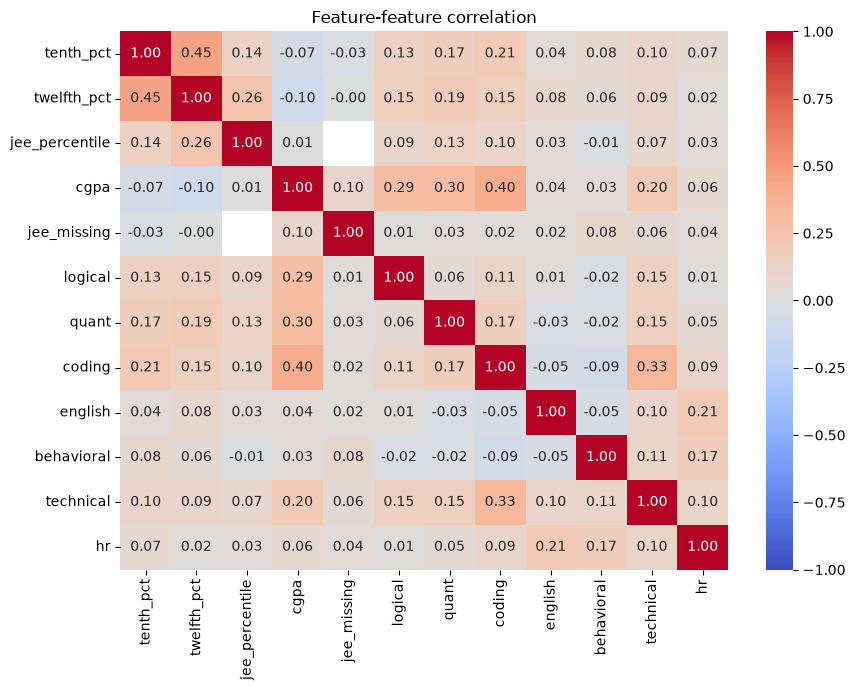

In [5]:
# Cell 5: redundancy check among the features
plt.figure(figsize=(9, 7))
sns.heatmap(d[candidates].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Feature-feature correlation")
plt.tight_layout()
plt.savefig(cfg.VISUALS_DIR / "10_feature_redundancy.png", dpi=150)
plt.show()